# First Supervisor Checkpoint: Consolidated Report

## Is the Vendor's Secret Sauce Priced? Bloomberg vs a Reproducible Sentiment Score on Identical Text

**Student:** Botushanski, Neill Liran | **Proposal:** A16-02 | **Supervisor:** Professor Hamid | **Prepared:** 2026-11-08

This report brings together everything the guide's first supervisor checkpoint asks for. It reads only saved outputs;
`python src/run_all.py` rebuilds all of them from the raw files. **No hypothesis test is presented.**

## Contents
1. Summary and the checkpoint pack
2. Research question and the supervisor's decisions
3. Data sources, inventory and verification
4. Raw-data validation
5. Sample coverage and attrition (Figure 1)
6. Timing and data-quality diagnostics (Figures 2 and 3)
7. The 188 headlines
8. Design decisions and proposals
9. Ten hand-checked observations and the terminal checks
10. Appendix: variable dictionary and reproduction

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()            # the Project 2 folder: walk up until design_decisions.md is found
while not (ROOT / "design_decisions.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
pd.set_option("display.max_columns", 50, "display.width", 250)
def read(rel, **kw): return pd.read_csv(ROOT / rel, **kw)
def show_text(rel): print((ROOT / rel).read_text(encoding="utf-8"))
def show_image(rel, width=900): display(Image(filename=str(ROOT / rel), width=width))

# Part 1. Summary and the checkpoint pack

**Project:** Is the Vendor's Secret Sauce Priced? Bloomberg vs a Reproducible Sentiment Score on Identical Text (proposal A16-02)
| **Student:** Botushanski, Neill Liran | **Prepared:** 2026-11-08

Nothing in this pack is a test of the hypothesis. Every number below is in `outputs/tables/checkpoint_1_facts.csv` with
the file it comes from.

### 1. The seven items

| # | Item the guide asks for | Where it is | Status |
|---|---|---|---|
| 1 | Completed design-decision log | `design_decisions.md` | Brief and supervisor items recorded (S1-S4); pull decisions B1-B6 approved; headline source decided (D1); P1-P6 proposed; E1-E2 open |
| 2 | Data manifest | `manifests/data_manifest.csv` | 12 rows: 9 available and validated, 3 RiskLab cross-check files still to copy |
| 3 | Bloomberg pilot and field definitions | Pilot_Checks and Field_Check sheets; `manifests/bloomberg_source_log.csv` | 7/7 terminal checks PASS; 26 fields confirmed in FLDS; 42 source-log rows with hashes |
| 4 | Sample-coverage table | `outputs/tables/coverage_by_year.csv` (+ size, sector, headline tables); `manifests/sample_attrition.csv` | 759,846 member security-days, 630 securities, 1,508 trading days; 82.0% carry a vendor sentiment value |
| 5 | Ten hand-checked observations | `outputs/diagnostics/hand_checks.csv` | 10/10 PASS, raw workbook cell to panel variable |
| 6 | One preliminary descriptive figure | `outputs/figures/fig1_vendor_coverage.png` | Plus Figure 2 (timing risk) and Figure 3 (score distribution) |
| 7 | Written list of unresolved data limitations | Section 4 below | 9 items |

### 2. What has been verified

- **Raw files.** 11/11 raw files match the SHA-256 recorded on the terminal; `News_Articles.csv` was copied
  byte-for-byte from the RiskLab drive (hash matches the RiskLab catalogue).
- **Validation.** 76 checks on schemas, keys, ranges, calendars, timing and joins; 4 flags, all explained
  (holiday values, the weekend gap, and two headline-file problems).
- **Joins.** No duplicate keys, no many-to-many joins; every universe ticker is in the identifier table; the 499 universe
  security-days without a market row are firms delisted or acquired during the month (497) or not yet listed (2).
- **Terminal checks.** Prices, volume, total-return index and the vendor score match HP/GP on the terminal, including the
  AAPL 4-for-1 split (unadjusted / adjusted = 4.00, no jump in the total-return index).
- **Hand checks.** Ten random security-days traced from the raw workbook cells through the export to the panel, with both
  returns recomputed by hand: all match.

### 3. Decisions that need the supervisor's approval

| Id | Proposal (design_decisions.md, section 7) | Alternative |
|---|---|---|
| P1 | Vendor value dated D is usable from the open of D; holiday values from the next open; never carried forward | - |
| P2 | Returns from total-return ratios (close-to-close) and split-adjusted open/close (open-to-close) | Price-only returns |
| P3 | One ticker per company per day; use the other exchange ticker on exchange-switch days (42 security-days) | Drop those days |
| P4 | Member on day t = member at the latest month-end strictly before t | Daily membership (about 1,500 bulk requests) |
| P5 | Headline subset: conservative cutoff (supervisor); compare with the vendor value dated the next weekday, same-day value as sensitivity | Average the two; or keep only the 33 unambiguous headlines |
| P6 | Keep flagged headlines, report with and without them | Delete the 4 flagged rows |

### 4. Unresolved data limitations

1. **Identical text is not yet available at scale (O1).** RiskLab holds no larger Bloomberg headline archive. The fallback
   file has 188 headlines for 19 firms from 95 public sources and 0 from bloomberg.com, with dates
   but no times. They cover 0.025% of member security-days. Whether Bloomberg's daily value scored these exact
   stories cannot be verified without story identifiers. A Bloomberg headline export is not being pursued (D1), so this is the
   primary identical-text sample.
2. **Story-to-value assignment is ambiguous.** For 149 of the 182 headlines with any vendor value, two candidate daily
   values could contain the story (before or after 09:20).
3. **Weekend gap (O6).** Monday values carry 4.8 scored stories per security-day against 14.5 on Tuesday-Thursday
   (holidays 6.0): consistent with a 24-hour window, so news from Friday 09:20 to Sunday 09:20 is in no daily value.
   27 Friday and 3 Saturday headlines are exposed. Not confirmed with Bloomberg; treated as an assumption.
4. **Vendor regime change around 2022 (O7).** Exact zeros fall from 47.2% of values (2020) to 12.7% (2023) and story counts
   roughly halve; full-sample normalisation would leak this change.
5. **Coverage rises with size (O8).** 74.6% of smallest-quintile security-days have a vendor value vs 94.9% of the
   largest; comparisons must be on identical observations.
6. **Headline-file quality (O9).** 3 headlines' URL dates differ from the file date by more than 3 days and 1 has no URL;
   the file's selection rule (ESG-themed, hand-collected) is undocumented.
7. **Intra-month index changes (B2/P4).** Additions enter at the next month-end; 497 security-days fall after a firm's last
   market row.
8. **Classifications are current only.** GICS is today's value and blank for 60 inactive names (BICS used); index weights
   were not entitled.
9. **RiskLab cross-check files not yet copied (O4).** `Daily_Average_Sentiment_Score.csv`, `SP500_NEWS_SENTIMENT_DAILY_AVG.csv`
   and `retail_proxy.csv` are on the RiskLab drive; they are cross-checks only.

### 5. Questions for the supervisor

1. D1: I am not pursuing the Bloomberg Help export question; the 188-headline subset is the primary sample. Is that acceptable?
2. P5: which vendor value should the reproducible score be compared with for each headline: the next-weekday value, the
   same-day value, or their average?
3. E2: primary outcome horizon, open-to-close on the value date (`ret_oc_d0`) or next-day close-to-close (`ret_cc_d1`)?
4. E2: primary reproducible scoring rule, a finance lexicon (Loughran-McDonald) or a finance transformer (FinBERT), with the
   other as robustness?
5. O6: should Friday and Saturday headlines stay in the identical-text sample, given the weekend gap?
6. S3: may the secondary exercise on the broad vendor panel (622,570 security-days with sentiment and a next-day return)
   start now, or only after the primary design is frozen?

# Part 2. Research question and the supervisor's decisions

### 2. Supervisor approval record

#### 2.1 Reply on the headline data and the pull plan (received by 2026-11-06)

My message of 2026-11-03 asked whether RiskLab holds a larger headline archive, which fallback the supervisor preferred if not, and whether the proposed terminal pull (B1 to B6) was acceptable. Professor Hamid's reply, reproduced exactly as I received it:

> Our current RiskLab catalogue does not contain a larger Bloomberg headline archive suitable for an identical-text comparison. The other public-web news files are not the same Bloomberg-scored universe.
> Please preserve the identical-text comparison as the primary design. First confirm with Bloomberg Help whether headlines, identifiers, timestamps, and ticker mappings may be exported for this academic project. I guess uo can do F1 twice to talk to them. If permitted, begin with a small pilot. If not, use the 188-headline subset, clearly report its selection and coverage, and use a conservative return cutoff. Do not reframe the primary test as a broad same-firm-day comparison. For the reframing we can talk about it later. Not now.
> You may run the broader Bloomberg daily-sentiment analysis as a separate secondary exercise, but it cannot identify Bloomberg's incremental value on identical text.
> Your proposed terminal pull is otherwise approved. Keep 2020–2025 as the analysis period, using July 2019 and January 2026 only as buffers. Use point-in-time membership, total returns, story counts, and strict information-timing rules. The existing local sentiment files can serve as cross-checks. These are all fine. Thanks you doing great!

What it settles: S1 to S4 below; B1 to B6 approved; O1 has a fixed path; O4 resolved.

#### 2.2 Fixed by the supervisor (2026-11-06)

- **S1 Identical text stays the primary design.** The primary test compares Bloomberg's score and the reproducible score on the same headlines. It is not reframed as a broad same-firm-day comparison; any reframing is a later conversation.
- **S2 Headline source, in order.** (1) Ask Bloomberg Help (HELP key twice) whether headlines, story identifiers, timestamps and ticker mappings may be exported for this academic project. (2) If permitted, start with a small pilot export. (3) If not, use the 188-headline subset of `News_Articles.csv`, report its selection and coverage, and use a conservative return cutoff.
- **S3 Secondary exercise allowed.** The broader analysis of Bloomberg's daily sentiment across the S&P 500 may be run as a separate, clearly labelled secondary exercise. It cannot identify Bloomberg's incremental value on identical text and is never presented as the primary test.
- **S4 Pull approved.** Analysis period 2020-2025; July 2019 and January 2026 are buffers only. Point-in-time membership, total returns, story counts and strict information-timing rules.

#### 2.3 Decided by the student (2026-11-08)

- **D1 Headline source.** The Bloomberg Help question in S2 (step 1) is not being pursued; I treat it as optional. The primary
  identical-text sample is therefore the S2 fallback: the 188-headline subset of `News_Articles.csv`, with its selection and
  coverage reported and a conservative return cutoff (P5, P6). S2's wording named the Help question as the first step, so I
  will mention this choice to the supervisor at the first checkpoint. *Supervisor approval: pending.*

The first checkpoint still needs: this log, the data manifest, the Bloomberg pilot and field definitions, a coverage table, ten hand-checked observations, one descriptive figure and the list of unresolved data limitations (guide, "First supervisor checkpoint").

### 3. Fixed by the brief

- **F1 Question.** Does the divergence between Bloomberg's proprietary news sentiment and a reproducible lexicon/transformer score on the same headlines carry information for subsequent returns?
- **F2 Hypothesis.** The divergence is mostly noise: it does not robustly predict returns beyond the reproducible score (honest null on a "black-box premium").
- **F3 Unit, outcome, estimand.** Security-day; next-day or short-horizon stock return; incremental out-of-sample content of the vendor score on identical text, against the reproducible-score-only model.
- **F4 Sample.** S&P 500 single names, 2020-2025 daily.
- **F5 Methods.** Primary: returns on reproducible score + divergence, HAC/clustered SE, encompassing / Diebold-Mariano. Robustness: purged CV, reproducible-only vs reproducible+vendor features, deflated Sharpe ratio.
- **F6 Data rule.** Bloomberg only for end-of-day, daily, reference, document or event data. Every minute-level series comes from `C:\risklab\data\intraday_data`.

# Part 3. Data sources, inventory and verification

### 3.1 Data manifest (one row per construct)

In [2]:
display(read("manifests/data_manifest.csv"))

dataset_id,source_path,provider,construct,role,unit,frequency,start,end,join_keys,point_in_time_status,adjustment,currency,timezone,license,validation_status,exclusions,notes
BBG-P2-UNIVERSE,data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/universe_snapshots.csv,Bloomberg,S&P 500 members at each month-end (INDX_MWEIGHT_HIST),Point-in-time universe (P4),membership,monthly,2019-12-31,2025-12-31,ticker_exch; snapshot_date,point-in-time by construction; intra-month changes not seen,,,,Bloomberg terminal licence; no redistribution,AVAILABLE; validated (02),weights not entitled (blank),"36,782 rows; 73 snapshots; 503-506 members; 635 tickers / 617 companies"
BBG-P2-SECURITIES,data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/securities.csv,Bloomberg,"Identifiers, status, currency, GICS (current), composite FIGI, BICS",Join keys; company link; sector,,static,2026-11-06,2026-11-06,ticker_exch; id_bb_global; composite_id_bb_global,current snapshot only,,USD (all),,Bloomberg terminal licence; no redistribution,AVAILABLE; validated (02),GICS blank for 60 inactive names (BICS used),635 rows
BBG-P2-MARKET,data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/market_daily.csv,Bloomberg,"Open, close, total-return index, volume (exchange and composite), market cap",Outcomes (returns) and controls,USD/share; index; shares; USD millions,daily (trading days),2019-07-01,2026-01-30,ticker_exch; date,EOD as of 2026-11-06,prices split-adjusted; TRI anchored 2019-07-01 (ratios only),USD,exchange close,Bloomberg terminal licence; no redistribution,AVAILABLE; validated (02); 10 hand checks (07),,"978,472 rows"
BBG-P2-NEWS,data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/news_daily.csv,Bloomberg,"NEWS_SENTIMENT_DAILY_AVG, story counts (all, pos, neg, neutral), NEWS_HEAT",Main signal (vendor score) and coverage,"score [-1,1]; stories; heat [0,4]",daily (weekdays incl. holidays),2019-07-01,2026-01-30,ticker_exch; date,value dated D known 09:20 New York on D (FLDS),none; blank = no value (never filled),,24h to 09:20 New York; heat at local midnight,Bloomberg terminal licence; no redistribution,AVAILABLE; validated (02); 10 hand checks (07),,"1,070,056 rows; weekend gap O6"
BBG-P2-EARNINGS,data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/earnings_history.csv,Bloomberg,"Earnings announcement dates, times, EPS",Optional control,EPS per share,event,,,ticker_exch; announcement_date,history as of 2026-11-06,,USD,times look like New York (not stated),Bloomberg terminal licence; no redistribution,AVAILABLE; validated (02),,"62,096 rows; 627 securities; 8 delisted names empty"
BBG-P2-INDEX,data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/index_daily.csv,Bloomberg,"SPX open/close, SPXT, VIX",Market return; regime,index points,daily,2019-07-01,2026-01-30,security; date,EOD,none,USD,close,Bloomberg terminal licence; no redistribution,AVAILABLE; validated (02),,"4,996 rows"
BBG-P2-RAW-WORKBOOK,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,Bloomberg,Raw pull workbook (formulas + cached values),Official raw file; source of the hand checks,,,,,,,,,,Bloomberg terminal licence; no redistribution,AVAILABLE; hash matches terminal record,,Plus _values copy and the Supplement workbook (+ _values)
RL-114CB44BEECC,data/raw_risklab/News_Articles.csv,RiskLab (Google Drive),Headlines: Company; Date; Headline; URL,"Text for the reproducible score (fallback sample, S2)",text,event (date only),2020-01-15,2025-10-29,Company -> ticker_exch at the latest snapshot,dates only; no times,,,unknown,proprietary-no-redistribution,"AVAILABLE; copied byte-for-byte 2026-11-08 (37,018 bytes; SHA-256 53bff1c0...)","flags: 3 URL-date mismatches, 1 non-URL (P6)",188 headlines; 19 firms; 0 from bloomberg.com
RL-1EBA802A51B7,Google Drive file 1Sr5g2nEJDKKdle8EKyj71mcOJIlPjgPQ (Daily_Average_Sentiment_Score.csv),RiskLab,Vendor sentiment (NW020) and call implied vol (RK074) for part of the sample,Cross-check only (S4),score; vol,daily,2019-01-01,2025-

### 3.2 Bloomberg source log (every field and file, with hashes)

In [3]:
display(read("manifests/bloomberg_source_log.csv"))

source_type,provider,terminal_function,security_or_series_id,field,field_description,frequency,start,end,currency,units,timezone,adjustment,retrieval_date,file_name,file_hash,notes
reference,Bloomberg,BDS,SPX Index (73 month-ends),INDX_MWEIGHT_HIST,Index members and percent weight as of END_DATE_OVERRIDE,monthly,2019-12-31,2025-12-31,,ticker,,,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Universe. Weight column returned -2.42E-14 for all (not entitled); membership only.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),NAME,DS002 Name,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),ID_BB_GLOBAL,ID135 exchange-level FIGI,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),ID_ISIN,ID005 ISIN,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),TICKER_AND_EXCH_CODE,DX657 ticker and exchange,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),EQY_PRIM_EXCH,Primary exchange,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static. GICS/EQY_PRIM_EXCH missing for 60 acquired/delisted names.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),MARKET_STATUS,PR286 market status,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),SECURITY_TYP,DS213 security type,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),CRNCY,DS004 pricing currency,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.
reference,Bloomberg,BDP,635 S&P 500 members 2019-12-31..2025-12-31 (securities.csv),COUNTRY_ISO,DS458 country ISO,snapshot,2026-11-06,2026-11-06,,text,,current value only,2026-11-06,data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,sha256:c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,Sheet Static.


### 3.3 Raw files and their SHA-256

In [4]:
display(read("outputs/diagnostics/raw_file_inventory.csv"))

file,bytes,rows_excl_header,sha256,recorded_sha256,hash_matches_record
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/README.txt,1737,,ed2b061a49522c4efff3ffd9fdf240878e6576e13a508e44d6df9fe3883c2614,,
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/SHA256SUMS.txt,846,,e040fe6f36e102c9fa0b2a1a96644537d827f82da2f92fb3db2095ba17cd0c35,,
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/bloomberg_source_log.csv,13924,35.0,2dfdd149b56477d3bba4060251308ae94f1c67fc38d2f56dc66aa92943085985,2dfdd149b56477d3bba4060251308ae94f1c67fc38d2f56dc66aa92943085985,True
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/earnings_history.csv,3086404,62096.0,3ee107491d59e3dddec34bda745308cfd070c6e55056780a791a03c99f370370,3ee107491d59e3dddec34bda745308cfd070c6e55056780a791a03c99f370370,True
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/index_daily.csv,164534,4996.0,55e663672030ff2c37820cf72c00d15dbadbea98b54bbfabb992db46c4b4261d,55e663672030ff2c37820cf72c00d15dbadbea98b54bbfabb992db46c4b4261d,True
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/market_daily.csv,64282828,978472.0,725af132da5b1c3980384bd52a050465b41c7209116c766393d6f82755459efb,725af132da5b1c3980384bd52a050465b41c7209116c766393d6f82755459efb,True
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/news_daily.csv,43826214,1070056.0,60110f72564a56a33b13f89af75136c7c0bbc6fad14b326c8440864df39460bb,60110f72564a56a33b13f89af75136c7c0bbc6fad14b326c8440864df39460bb,True
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/securities.csv,158787,635.0,f18d08bd4f3dfb7fce30433b8aebfd777edfd5d367ecf09780b48d80ab7e68f9,f18d08bd4f3dfb7fce30433b8aebfd777edfd5d367ecf09780b48d80ab7e68f9,True
data/raw_bloomberg/20261106/P2_Bloomberg_Export_20261106/universe_snapshots.csv,707126,36782.0,dd59626c80d9affbd0bcbc05a9b76b1e3cf6731f1daeb832850cefe53a4f0616,dd59626c80d9affbd0bcbc05a9b76b1e3cf6731f1daeb832850cefe53a4f0616,True
data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106.xlsx,115948759,,c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,c0e3898123a45bdd436a17b525d6bd9d824272202493490750678a72503c33ed,True


# Part 4. Raw-data validation

In [5]:
show_text("outputs/diagnostics/02_raw_validation_summary.txt")

02_raw_validation: 76 checks, 4 flagged

[files]
  PASS  Raw files whose SHA-256 matches the hash recorded on the terminal: 11/11
  PASS  News_Articles.csv SHA-256 starts with the RiskLab catalogue value 53bff1c0: 53bff1c0

[securities]
  PASS  Rows (exchange tickers): 635
  PASS  Duplicate ticker_exch: 0
  PASS  Duplicate exchange-level FIGI (id_bb_global): 0
  PASS  Companies (composite FIGI): 617
  PASS  Companies with two exchange tickers: 18  (AEP UN / AEP UW; COO UN / COO UW; CPB UN / CPB UW; EXPD UN / EXPD UW; FISV UN / FISV UW; DOC UN / DOC US; HST UN / HST UW; KMB UN / KMB UW; WMT UN / WMT UW; GRMN UN / GRMN UW; ROP UN / ROP UW; HON UN / HON UW; PLTR UN / PLTR UW; DPZ UN / DPZ UW; BKR UN / BKR UW; EVRG UN / EVRG UW; APA UN / APA UW; LIN UN / LIN UW)
  PASS  Pricing currency other than USD: 0
  PASS  Missing GICS sector (inactive names): 60  (BICS sector is filled for all: 635)
  PASS  Missing ISIN: 1  (1844053D US)
  PASS  Market status counts: ACTV 567; ACQU 49; DLST 10; INAC

### 4.1 Every check

In [6]:
display(read("outputs/diagnostics/raw_validation_checks.csv"))

area,check,value,expected,status,detail
files,Raw files whose SHA-256 matches the hash recorded on the terminal,11/11,all,PASS,
files,News_Articles.csv SHA-256 starts with the RiskLab catalogue value 53bff1c0,53bff1c0,53bff1c0,PASS,
securities,Rows (exchange tickers),635,635,PASS,
securities,Duplicate ticker_exch,0,0,PASS,
securities,Duplicate exchange-level FIGI (id_bb_global),0,0,PASS,
securities,Companies (composite FIGI),617,617,PASS,
securities,Companies with two exchange tickers,18,18,PASS,AEP UN / AEP UW; COO UN / COO UW; CPB UN / CPB UW; EXPD UN / EXPD UW; FISV UN / FISV UW; DOC UN / DOC US; HST UN / HST UW; KMB UN / KMB UW; WMT UN / WMT UW; GRMN UN / GRMN UW; ROP UN / ROP UW; HON UN / HON UW; PLTR UN / PLTR UW; DPZ UN / DPZ UW; BKR UN / BKR UW; EVRG UN / EVRG UW; APA UN / APA UW; LIN UN / LIN UW
securities,Pricing currency other than USD,0,0,PASS,
securities,Missing GICS sector (inactive names),60,60 (documented),PASS,BICS sector is filled for all: 635
securities,Missing ISIN,1,small,PASS,1844053D US


### 4.2 Join report

In [7]:
display(read("outputs/diagnostics/join_report.csv"))

join,left_rows,matched,unmatched,many_to_many,unmatched_reasons
"universe security-days -> outcomes_daily (ticker_exch, date)",759846,759347,499,0,after the last Bloomberg market row (delisted or acquired during the month): 497; before the first Bloomberg market row (new listing or spin-off): 2
universe security-days -> vendor signal dated the same trading day,759846,759303,543,0,


# Part 5. Sample coverage and attrition

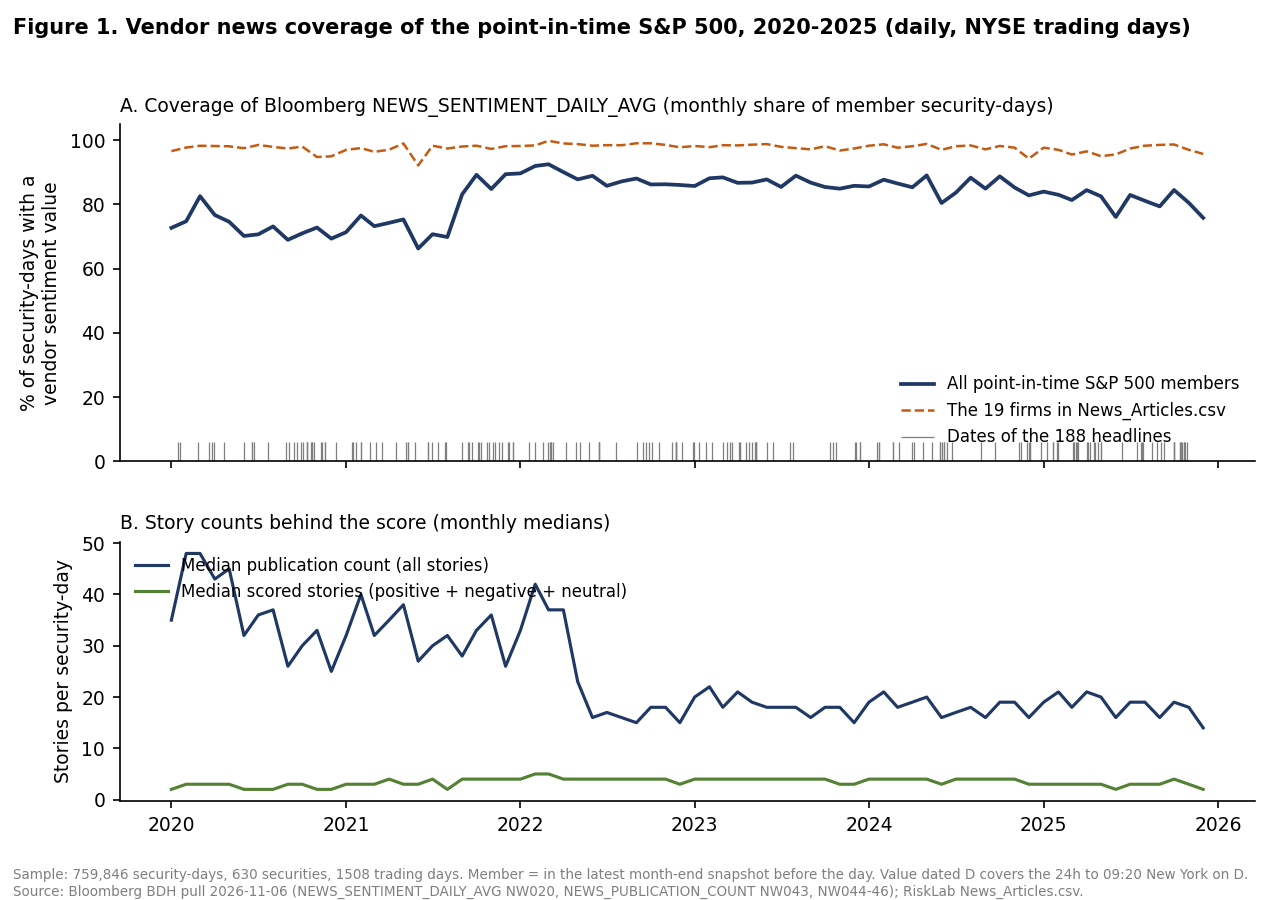

In [8]:
show_image("outputs/figures/fig1_vendor_coverage.png", width=900)

**Reading Figure 1.** Coverage of the vendor score is high but not complete: about four in five member security-days carry a
value, with a dip in 2020-21. The 19 headline firms are large caps and covered on about 98% of their member days. Mean story
counts fall from about 89 a day (2020-21) to about 48 (2023-25), over the same period in which the share of exact zeros drops
(Part 6).

### 5.1 Coverage by year

In [9]:
display(read("outputs/tables/coverage_by_year.csv"))

year,trading_days,avg_members_per_day,securities,security_days,pct_with_vendor_row,pct_with_sentiment,pct_with_scored_story,mean_publication_count,median_publication_count,mean_scored_stories,sentiment_mean,sentiment_sd,sentiment_p05,sentiment_p50,sentiment_p95,pct_sentiment_exactly_0
2020,253.0,505.0870,525.0,127787.0,99.6165,73.0692,68.8059,89.2366,35.0,12.5340,0.0274,0.2807,-0.4865,0.0,0.6321,47.1903
2021,252.0,505.0000,522.0,127260.0,99.7038,76.9904,67.9452,89.0051,32.0,15.3801,0.0177,0.3420,-0.6321,0.0,0.6639,41.3828
2022,251.0,503.8207,520.0,126459.0,99.9510,88.3377,87.3951,65.1815,22.0,12.8324,-0.0411,0.4828,-0.8647,0.0,0.8647,11.3149
2023,250.0,503.0000,520.0,125750.0,99.9634,86.7388,84.9885,48.5871,18.0,13.7473,-0.0288,0.3300,-0.6368,0.0,0.6321,12.7079
2024,252.0,503.0913,523.0,126779.0,99.9858,85.7374,83.6842,48.7753,18.0,12.6799,-0.0166,0.2153,-0.4021,0.0,0.3290,16.1955
2025,250.0,503.2440,525.0,125811.0,99.9777,81.2902,80.9055,48.2500,18.0,10.3723,-0.0047,0.1829,-0.3101,0.0,0.2918,27.0758
2020-2025,1508.0,503.8767,630.0,759846.0,99.8656,82.0041,78.9194,64.9035,23.0,12.8571,-0.0092,0.3243,-0.6321,0.0,0.6321,25.1009


### 5.2 Coverage by size quintile (market cap at the start of each month)

In [10]:
display(read("outputs/tables/coverage_by_size_quintile.csv"))

Unnamed: 0,security_days,median_cap_musd,pct_with_sentiment,mean_publication_count,mean_scored_stories,sentiment_mean
Q1 (smallest),152330.0,10791.2678,74.6222,26.1590,4.9943,-0.0244
Q2,152266.0,18792.5480,75.4646,26.2449,5.0527,-0.0081
Q3,151534.0,30829.1319,80.4546,33.8425,6.5049,-0.0071
Q4,152266.0,53714.5816,84.6565,46.7408,8.6065,-0.0066
Q5 (largest),151364.0,157178.3338,94.8931,191.8649,37.5450,-0.0022


### 5.3 Coverage by sector (BICS, current classification)

In [11]:
display(read("outputs/tables/coverage_by_sector.csv"))

bics_industry_sector,securities,security_days,pct_with_sentiment,mean_publication_count,sentiment_mean
"Consumer, Non-cyclical",128.0,163283.0,81.8536,47.0870,-0.0126
Financial,115.0,142420.0,80.2689,61.0980,-0.0110
Industrial,88.0,104661.0,76.0159,38.3969,-0.0038
"Consumer, Cyclical",82.0,96771.0,86.2035,69.1392,-0.0064
Technology,75.0,87513.0,83.6287,115.0193,-0.0013
Communications,50.0,56137.0,88.7294,145.0215,-0.0162
Utilities,33.0,44379.0,79.1838,27.4532,-0.0221
Energy,37.0,37125.0,85.0263,52.0664,-0.0042
Basic Materials,22.0,27557.0,81.4711,31.0163,-0.0059


### 5.4 Sample attrition: from the point-in-time universe to the analysis samples

In [12]:
display(read("manifests/sample_attrition.csv"))

step,rule,decision,securities_or_firms,security_days_or_headlines,parent_step,dropped_vs_parent,notes
1,"Universe security-days: members at the latest month-end before each NYSE trading day, 2020-01-02 to 2025-12-31",P4 (proposed),630,759846,,,
1b,... of which the company's other exchange ticker is used that day (exchange switch),P3 (proposed),3,42,1,,
2,... with a Bloomberg market row,,630,759347,1,499.0,
3,... with a close price on the day,,629,759228,2,119.0,
4,... with both same-day returns (ret_cc_d0 and ret_oc_d0),,629,759225,3,3.0,
5,Universe security-days with a vendor news row (any field),,630,759303,1,543.0,
6,... with a vendor sentiment value (NEWS_SENTIMENT_DAILY_AVG),,630,623105,5,136198.0,
7,... with sentiment and a same-day open-to-close return (ret_oc_d0),,629,622618,6,487.0,
8,... with sentiment and a next-day close-to-close return (ret_cc_d1),,629,622570,6,535.0,Main vendor-signal sample for later work; nothing is estimated at checkpoint 1.
A1,Headlines in News_Articles.csv dated 2020-2025,,19,188,,,


# Part 6. Timing and data-quality diagnostics

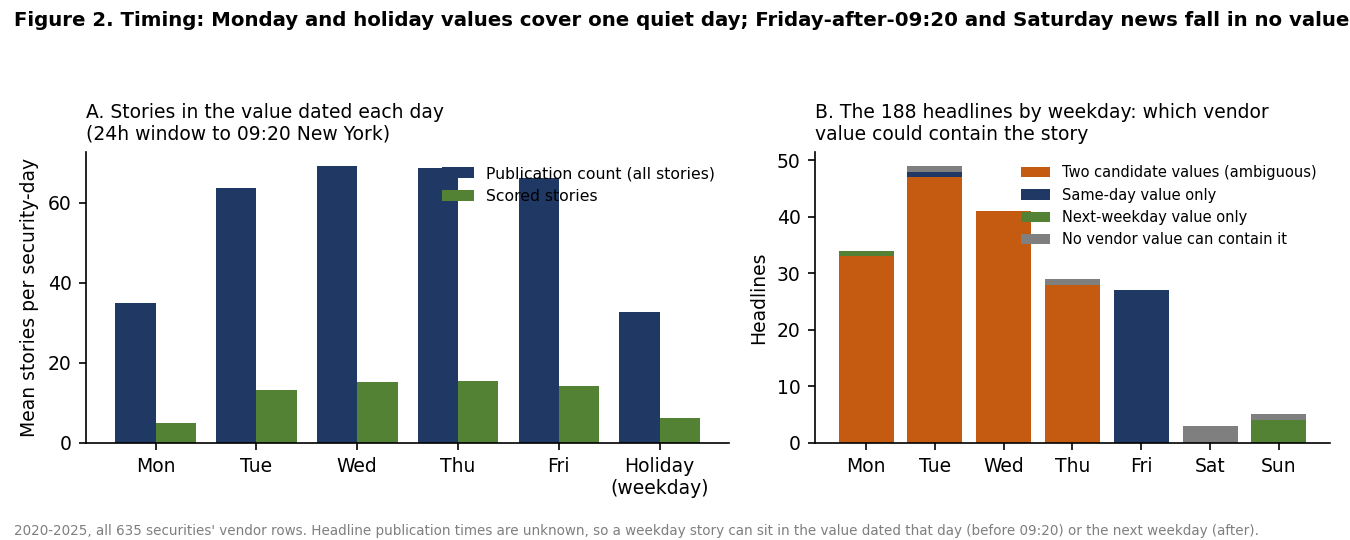

In [13]:
show_image("outputs/figures/fig2_timing_window.png", width=900)

**Reading Figure 2.** The value dated each weekday covers the 24 hours to 09:20 New York. Monday's and holiday values carry about
a third of a normal day's scored stories, which fits a window covering one quiet day; news from Friday 09:20 to Sunday 09:20
appears to fall in no value. Panel B shows the consequence for the headlines: for most of them two values could contain the
story, and a few can be in none.

In [14]:
display(read("outputs/tables/vendor_counts_by_value_day.csv"))

kind,pub,scored,share
Mon,34.848315,4.843649,0.517707
Tue,63.711835,13.030529,0.843971
Wed,69.178230,15.102828,0.879568
Thu,68.686889,15.289754,0.875470
Fri,66.204103,14.262017,0.870485
Holiday\n(weekday),32.785369,6.042164,0.572726


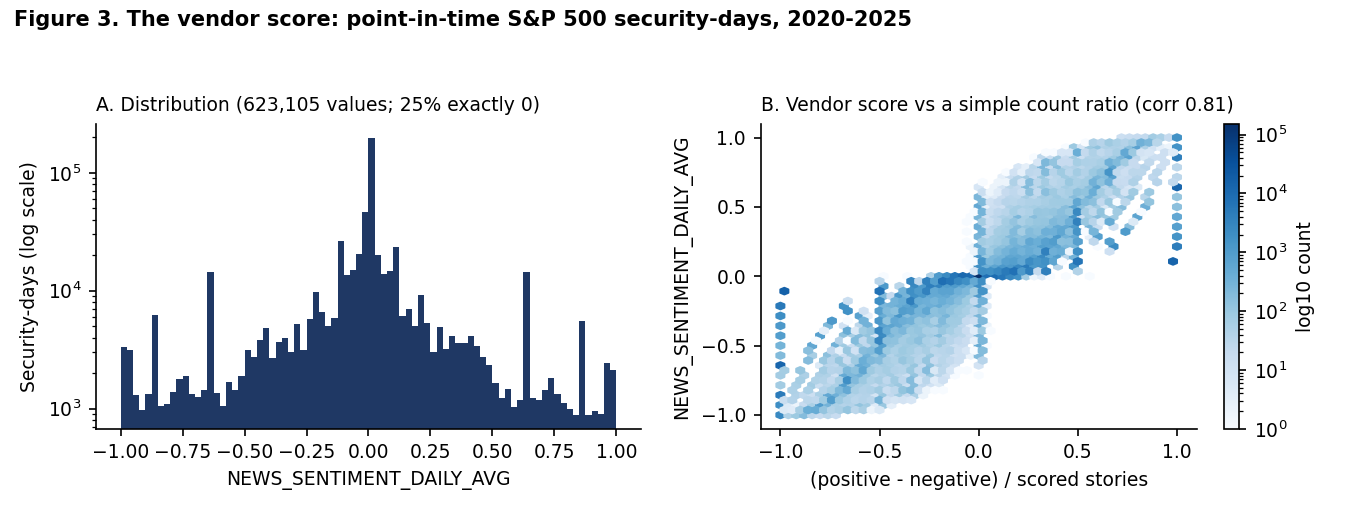

In [15]:
show_image("outputs/figures/fig3_sentiment_distribution.png", width=900)

**Reading Figure 3.** A quarter of values are exactly 0; most of these have scored stories with positive = negative, so they are
real neutral readings, not missing data. A plain count ratio tracks the vendor score closely (correlation about 0.8), which is
descriptive context for the black-box question, not a test of it.

In [16]:
display(read("outputs/tables/vendor_field_summary.csv"))

pct_missing,count,mean,std,min,1%,5%,50%,95%,99%,max
17.9959,623105.0,-0.0092,0.3243,-1.0,-0.9502,-0.6321,0.0000,0.6321,0.9050,1.0
0.1373,758803.0,64.9035,189.7858,0.0,2.0000,4.0000,23.0000,221.0000,835.0000,15526.0
1.9667,744902.0,1.4364,6.3306,0.0,0.0000,0.0000,0.0000,6.0000,18.0000,665.0
4.9979,721870.0,1.7560,9.1024,0.0,0.0000,0.0000,0.0000,6.0000,23.0000,1415.0
0.2132,758226.0,9.1583,35.2433,0.0,0.0000,0.0000,2.0000,33.0000,156.0000,5929.0
5.8980,715030.0,12.8571,44.2226,0.0,0.0000,0.0000,3.0000,46.0000,198.0000,6245.0
1.5783,747853.0,0.5663,0.5323,0.0,0.0000,0.0000,0.4035,1.6250,2.4826,4.0
16.1576,637073.0,0.9537,1.4417,0.0,0.0000,0.0000,0.0000,4.0000,4.0000,4.0


### 6.1 Returns (sanity check only; no return is related to any signal here)

In [17]:
display(read("outputs/tables/return_summary.csv"))

count,mean,std,min,1%,50%,99%,max
759225.0,0.00053,0.02346,-0.61827,-0.06436,0.00063,0.06585,0.49881
759228.0,0.00012,0.01858,-0.49367,-0.05043,0.00025,0.05109,0.65956
759178.0,0.00054,0.02346,-0.61827,-0.06436,0.00063,0.06587,0.49881


# Part 7. The 188 headlines

In [18]:
display(read("outputs/tables/headline_coverage_by_firm.csv"))

Company,headlines,first,last,member_at_date,vendor_value_same_day,vendor_value_next_weekday,no_vendor_value,return_available,date_or_url_flag
XOM,12,2020-06-02,2024-05-29,12,11,10,1,12,0
GOOGL,12,2020-06-17,2025-10-24,12,11,11,0,12,0
DUK,12,2020-10-12,2025-10-01,12,11,9,1,12,0
TSLA,11,2020-03-19,2025-04-17,9,8,8,2,9,1
PFE,11,2020-01-20,2025-09-11,11,10,5,1,11,0
JPM,11,2020-01-15,2025-10-17,11,11,8,0,11,0
JNJ,11,2020-10-12,2025-10-29,11,11,11,0,11,0
AMZN,11,2020-03-31,2024-06-24,11,11,10,0,11,0
GS,11,2020-10-22,2025-10-13,11,10,11,0,11,1
FCX,10,2020-09-03,2025-10-16,10,8,9,0,10,0


In [19]:
display(read("outputs/tables/headline_coverage_by_year.csv"))

year,headlines,firms,vendor_value_same_day,share_of_member_security_days_pct
2020,30,17,26,0.0235
2021,36,18,35,0.0283
2022,30,16,30,0.0237
2023,28,15,27,0.0223
2024,26,14,24,0.0205
2025,38,15,35,0.0302


### 7.1 Every headline with its validation flags and candidate vendor dates

In [20]:
a = read("data/interim/articles_aligned.csv")
display(a[["article_id", "Company", "Date", "Headline", "domain", "member_at_date", "vendor_date_if_before_0920", "vendor_date_if_after_0920", "vendor_sent_same_day", "vendor_sent_next_weekday", "first_tradable_day_conservative", "flag_url_date_mismatch", "flag_url_not_url"]])

[Output removed from the public copy: this table lists the RiskLab news headlines, which are proprietary and not redistributed.]


# Part 8. Design decisions and proposals

### 5. Data-acquisition decisions (proposed 2026-11-03; approved by the supervisor, section 2.1)

These shape what is pulled from the terminal. None of them involves a result. They are implemented in `src/00a_build_bloomberg_pull_workbook.py` and `config/project_config.yaml`.

#### B1. Pull window 2019-07-01 to 2026-01-30
- **Proposal:** pull six months before the study window and about one month after it. The study window (F4) does not change.
- **Why:** training-window rescaling (guide hint 3) and lagged controls need history before 2020-01-01; forward returns for late-December 2025 need January 2026.
- **Alternative:** pull exactly 2020-2025 (first months lose their lags; last days lose their outcomes).
- **Approval:** approved by Professor Hamid (reply in section 2.1, received by 2026-11-06).

#### B2. Universe: point-in-time S&P 500 members at month-ends
- **Proposal:** `INDX_MWEIGHT_HIST` on `SPX Index` at the 73 month-ends from 2019-12-31 to 2025-12-31; request data for the union of members. A security-day enters the panel if the security was a member at the latest month-end before it (rule to confirm).
- **Why:** includes firms that left the index, so the sample is not survivor-only.
- **Alternatives:** today's constituents (survivorship bias); daily membership (about 1,500 bulk requests instead of 73).
- **Known limitation:** a firm added and removed within one month is missed; additions are seen with up to a month's delay.
- **Approval:** approved by Professor Hamid (reply in section 2.1, received by 2026-11-06).

#### B3. Daily returns from the total-return index; prices split-adjusted only
- **Proposal:** daily returns from `TOT_RETURN_INDEX_GROSS_DVDS` (Bloomberg end-of-day). `PX_OPEN` and `PX_LAST` adjusted for splits and capital changes only (`CapChg=Y`, `CshAdjNormal=N`, `CshAdjAbnormal=N`, `UseDPDF=N`), so open-to-close and overnight returns can be formed if E1 needs them. First Rate one-minute stock files are used only for intraday timing checks and as a price cross-check (F6).
- **Alternatives:** returns from First Rate daily closes (the brief lists `intraday_data` for returns; dividends would need a separate source); dividend-adjusted prices.
- **To check on the pilot:** the AAPL 4-for-1 split (2020-08-31): unadjusted / adjusted close = 4.00, and no jump in the total-return index.
- **Approval:** approved by Professor Hamid (reply in section 2.1, received by 2026-11-06).

#### B4. News fields on every calendar day, never carried forward
- **Proposal:** news fields are pulled with `Days=A` (weekends kept) and `Fill=B` (blank when there is no value). Weekend stories are later mapped to the next trading day under E1. Days with no stories stay missing; they are never filled with the previous day's sentiment.
- **Why:** carrying sentiment forward would invent news; dropping weekends would lose stories.
- **Approval:** approved by Professor Hamid (reply in section 2.1, received by 2026-11-06).

#### B5. Field tiers
- **Proposal:** core = `NEWS_SENTIMENT_DAILY_AVG`, `NEWS_PUBLICATION_COUNT`, the five market fields, static identifiers and the universe. Optional = tone counts, the two NEWS_HEAT fields (an optional extension in the brief) and earnings announcements. Optional sheets are pulled only if no data-limit warning appears.
- **Approval:** approved by Professor Hamid (reply in section 2.1, received by 2026-11-06).

#### B6. Static classifications are current snapshots
- **Proposal:** GICS, ticker and status from `BDP` are today's values and are not used to infer past values (guide). FIGI (`ID_BB_GLOBAL`) is the stable join key.
- **Approval:** approved by Professor Hamid (reply in section 2.1, received by 2026-11-06).

### 6. Implementation record: the 2026-11-06 terminal pull

Pulled on the RiskLab terminal (S/N 726910-173) on 2026-11-06 with `bloomberg_pull/P2_Bloomberg_Pull.xlsx`; copied unchanged
to `data/raw_bloomberg/20261106/` on 2026-11-08 (every SHA-256 matches the hashes recorded on the terminal). Source log:
`manifests/bloomberg_source_log.csv`. What differs from the plan in section 5, and why:

- **Index weights not entitled.** `INDX_MWEIGHT_HIST` returned membership but the weight column came back as Bloomberg's
  missing-number placeholder (-2.42E-14). Membership is all the design needs (B2); weights are not used.
- **Supplement pull.** `COMPOSITE_ID_BB_GLOBAL` (company-level FIGI), BICS sector/group/subgroup and composite (consolidated)
  volume were added in `P2_Bloomberg_Supplement_20261106.xlsx`, because `PX_VOLUME` on UN/UW tickers is one exchange only
  (median 31% of consolidated) and GICS is blank for 60 acquired or delisted names.
- **Units and anchors recorded from FLDS.** `CUR_MKT_CAP` from BDH is in USD millions (BDP gives full USD).
  `TOT_RETURN_INDEX_GROSS_DVDS` is anchored to the request start date, so only ratios are used (B3).
- **Universe size.** 73 snapshots, 503-506 members each, 635 exchange tickers = 617 companies (18 on two exchanges).
- **Field IDs mapped.** NW020 = `NEWS_SENTIMENT_DAILY_AVG`; RK074 = `HIST_CALL_IMP_VOL` (call implied volatility, not a
  sentiment field) in RiskLab's `Daily_Average_Sentiment_Score.csv`.
- **Pilot.** All seven terminal comparisons on Pilot_Checks passed (HP/GP vs workbook), including the AAPL 4-for-1 split.
  Check 3 (unadjusted close) was derived from HP's adjusted close x 4 because the HP settings dialog could not be operated
  remotely.

#### 6.1 Timing facts (FLDS, 2026-11-06) and empirical checks (2026-11-08)

- `NEWS_SENTIMENT_DAILY_AVG` (NW020) and the story counts (NW043-NW046) dated D are published 10 minutes before the US open on
  D and cover the previous 24 hours. A value dated D is known at about 09:20 New York time on D. Range [-1, 1].
- No values are dated Saturday or Sunday. **Values do exist on weekday market holidays** (39,842 security-days), contrary to
  the pull notes ("values on trading days only"). `outputs/diagnostics/02_raw_validation_summary.txt`.
- **Weekend gap (empirical).** Monday's value carries about a third of the scored stories of a Tuesday-Thursday value
  (4.8 vs 14.5 per security-day; holidays 6.0). This fits the FLDS 24-hour window: Monday's value covers mostly Sunday, so
  stories published from Friday 09:20 to Sunday 09:20 fall in no daily value (O6). Not confirmed with Bloomberg; treated as a
  documented assumption.
- `NEWS_HEAT_*` fields update at local midnight (a different clock); they are not used for timing.
- Zeros are real readings: 212,063 of 241,488 zero sentiment values have scored stories with positive = negative; a missing
  value means no scored stories (181,360 such rows). Neither is filled.

### 7. Proposals for checkpoint 1 (PROPOSED 2026-11-08; none chosen by results)

Implemented in `src/03`-`src/05` so the checkpoint numbers can be produced; each can be changed before estimation.

#### P1. Information timing of the vendor value
- **Proposal:** the value dated D is usable from the open of D. A value dated on a holiday is first usable at the next trading
  day's open; it is counted (`n_holiday_values_before`) but not merged into that day's value. No value is carried forward.
- **Outcome candidates that respect this timing:** `ret_oc_d0` (open D to close D) and `ret_cc_d1` (close D to close D+1).
  `ret_cc_d0` (close D-1 to close D) starts before the value is known; it is kept only for timing diagnostics.
- **Choice of primary horizon:** with E2, by the supervisor.

#### P2. Return construction
- `ret_cc` = TRI_t / TRI_{t-1} - 1 when t-1 is the previous NYSE day; `ret_oc` = PX_LAST_t / PX_OPEN_t - 1 (split-adjusted,
  so the adjustment cancels); `ret_co` = (1 + ret_cc) / (1 + ret_oc) - 1 (dividends fall here).
- One return in 972,599 could not be formed because a trading day is missing in between.

#### P3. One ticker per company per day; exchange switches
- **Proposal:** the unit is the exchange ticker that was the member in the snapshot; no snapshot lists a company twice
  (checked). When that ticker has no price on a day but the company's other exchange ticker does (EXPD, FISV and GRMN moved
  exchange mid-month), the other ticker is used for that day: 42 security-days.
- **Alternative:** drop those days (loses 42 security-days for three firms).

#### P4. Daily membership rule
- **Proposal:** a security is in the universe on trading day t if it was a member at the latest month-end snapshot strictly
  before t (2019-12-31 for January 2020). This is point-in-time and uses no later information.
- **Known limitation (B2):** a firm added mid-month enters at the next month-end; 497 universe security-days fall after a
  firm's last Bloomberg market row (acquired or delisted during the month) and stay in the attrition table.

#### P5. Aligning the 188 headlines (the primary identical-text sample, D1)
- **Conservative cutoff (supervisor, S2):** a headline is assumed known only after the end of its file date; its first tradable
  moment is the open of the first trading day strictly after that date.
- **Which vendor value contains the story:** publication times are unknown, so a weekday story sits in the value dated that day
  (if published before 09:20) or the next weekday (after). For 149 of the 182 headlines with any vendor value, both candidate
  values exist. Proposed rule, to freeze before scoring: compare against the value dated the next weekday (the later value
  must contain a story published on day d after 09:20, and the conservative cutoff already assumes after-hours), and report
  the same-day value as a sensitivity.
- **Alternative:** average the two candidate values; or drop the 149 ambiguous headlines (leaves 33).

#### P6. Headline-file exclusions
- **Proposal:** keep every headline but flag: 2 Tesla headlines dated before Tesla joined the index (excluded from the member
  sample by P4), 3 headlines whose URL date differs from the file date by more than 3 days (GS 2023-01-10 vs 2023-01-27,
  KO 2020-08-28 vs 2020-12-17, TSLA 2024-03-31 vs 2024-05-31) and 1 with no URL (TSLA 2025-04-17). Results are reported with
  and without the flagged rows (guide: quantify, flag, sensitivity; never delete silently).

### 8. Open issues (for the first checkpoint)

- **O1 Identical text (critical).** RiskLab holds no larger Bloomberg headline archive (supervisor, 2.1), and the Bloomberg
  Help export question is not being pursued (D1), so the primary sample is the 188-headline subset. Facts about it: 188 headlines, 19 large-cap firms, 2020-01-15 to 2025-10-29, 95 source domains, none from
  bloomberg.com, dates only (no times). They cover 0.025% of member security-days (0.66% of the 19 firms' security-days).
  Whether Bloomberg's daily value actually scored these stories cannot be verified without story identifiers.
- **O2 Day boundary.** Resolved by FLDS (6.1): the 24 hours to 09:20 New York on D. The weekend consequence is O6.
- **O3 Ticker changes and delistings.** Resolved for the panel: composite FIGI links the 18 two-exchange companies, three
  mid-month exchange switches are handled by P3, and BICS replaces GICS for the 60 names with no current GICS.
- **O4 Role of the RiskLab vendor files.** Resolved (cross-checks only). Not yet copied into `data/raw_risklab/`: the three
  files are on Professor Hamid's Google Drive and too large to move through the connector (2.9 MB, 3.8 MB, 95 MB).
- **O5 Terminal download limit.** Resolved: the pull was completed on a terminal without the limit (S/N 726910-173).
- **O6 Weekend gap.** Stories from Friday 09:20 to Sunday 09:20 appear to fall in no daily value (6.1). This affects 27
  Friday and 3 Saturday headlines in the primary sample and the meaning of Monday's value. Not confirmed with Bloomberg; treated
  as a documented assumption.
- **O7 Vendor regime change around 2022.** The share of exact zeros falls from 41-47% (2020-21) to 11-16% (2022-24), the
  standard deviation peaks at 0.48 in 2022, and the median story count falls from about 33 to 18. Whether Bloomberg changed
  its model or its source set is unknown; it makes full-sample normalisation unsafe and supports training-window rescaling
  (guide hint 3).
- **O8 Coverage rises with size.** 75% of smallest-quintile security-days have a vendor value vs 95% of the largest. Any
  comparison of the vendor and reproducible scores must be on identical observations (guide hint 4).
- **O9 Headline-file quality and selection.** The 188 headlines look hand-collected and ESG-themed, from mixed public sources
  (Reuters 32, CNBC 11, Guardian 7, ESG Today 7, ...), with the date problems in P6. The selection rule behind the file is
  not documented.

# Part 9. Ten hand-checked observations and the terminal checks

In [21]:
display(read("outputs/diagnostics/hand_checks.csv"))

check_id,ticker_exch,date,next_trading_day,slot,market_cells,news_cell,raw_sentiment,panel_sentiment,raw_px_open,raw_px_last,raw_tri_d,raw_tri_d1,hand_ret_oc_d0,panel_ret_oc_d0,hand_ret_cc_d1,panel_ret_cc_d1,snapshot_date,result
H01,PLD UN,2021-02-09,2021-02-10,466,Market!DUG412:DUJ412 and DUJ413,News_Core!BSQ595,0.0000,0.0000,106.92,107.42,111.4934,111.5972,0.004676,0.004676,0.000931,0.000931,2021-01-31,PASS
H02,RSG UN,2021-06-18,2021-06-21,503,Market!EEF502:EEI502 and EEI503,News_Core!BYI724,0.0318,0.0318,107.61,106.52,110.0604,112.0339,-0.010129,-0.010129,0.017931,0.017931,2021-05-31,PASS
H03,IEX UN,2022-06-29,2022-06-30,310,Market!CEG761:CEJ761 and CEJ762,News_Core!AUQ1100,-0.9502,-0.9502,182.03,181.08,187.2363,187.8050,-0.005219,-0.005219,0.003037,0.003037,2022-05-31,PASS
H04,BBY UN,2023-04-27,2023-04-28,78,Market!TU969:TX969 and TX970,News_Core!KY1402,-0.6321,-0.6321,71.65,73.53,83.1105,84.2295,0.026239,0.026239,0.013464,0.013464,2023-03-31,PASS
H05,BAC UN,2023-07-27,2023-07-28,74,Market!SS1031:SV1031 and SV1032,News_Core!KI1493,0.2142,0.2142,32.41,31.95,35.1296,35.0746,-0.014193,-0.014193,-0.001566,-0.001566,2023-06-30,PASS
H06,DAL UN,2023-12-01,2023-12-04,165,Market!ARF1120:ARI1120 and ARI1121,News_Core!YI1620,0.0055,0.0055,36.98,38.05,39.0360,39.1489,0.028935,0.028935,0.002892,0.002892,2023-11-30,PASS
H07,LOW UN,2024-11-11,2024-11-12,367,Market!CTP1357:CTS1357 and CTS1358,News_Core!BDK1966,0.0000,0.0000,273.81,274.51,303.3846,298.2897,0.002557,0.002557,-0.016794,-0.016794,2024-10-31,PASS
H08,GM UN,2025-03-18,2025-03-19,268,Market!BSY1442:BTB1442 and BTB1443,News_Core!AOE2093,0.0139,0.0139,49.35,48.67,51.7269,52.9172,-0.013779,-0.013779,0.023011,0.023011,2025-02-28,PASS
H09,MTD UN,2025-06-03,2025-06-04,412,Market!DFS1495:DFV1495 and DFV1496,News_Core!BKI2170,-0.1068,-0.1068,1140.00,1166.46,1166.4600,1169.6700,0.023211,0.023211,0.002752,0.002752,2025-05-31,PASS
H10,IP UN,2025-12-09,2025-12-10,317,Market!CGD1626:CGG1626 and CGG1627,News_Core!AVS2359,-0.0996,-0.0996,38.27,37.58,50.2122,52.2698,-0.018030,-0.018030,0.040978,0.040978,2025-11-30,PASS


### 9.1 How to check one by hand (H01: PLD UN on 2021-02-09)

1. Open `data/raw_bloomberg/20261106/P2_Bloomberg_Pull_20261106_values.xlsx` (no Bloomberg needed).
2. On **News_Core**, cell `BSQ595` holds the vendor score dated 2021-02-09: **0.0**.
3. On **Market**, cells `DUG412:DUJ412 and DUJ413` hold open, close and the total-return index on 2021-02-09, and the
   index on the next trading day (2021-02-10).
4. Open-to-close return = close / open - 1 = 107.42 / 106.92 - 1 = **0.004676**.
5. Next-day return = TRI(2021-02-10) / TRI(2021-02-09) - 1 = 111.5972 / 111.4934 - 1 = **0.000931**.
6. Both equal the panel values in `data/analytic/panel_security_day.csv.gz`.

### 9.2 The seven terminal checks (Pilot_Checks sheet, 2026-11-06)

In [22]:
display(read("outputs/diagnostics/pilot_terminal_checks.csv"))

check,what,security,field,date,workbook_value,terminal_value,result,where_read
1,"AAPL close before the split, adjusted",AAPL UW Equity,PX_LAST,2020-08-28,1.248075e+02,1.248075e+02,PASS,HP <GO> on AAPL UW Equity (default adjustment includes splits)
2,"AAPL close on the split date, adjusted",AAPL UW Equity,PX_LAST,2020-08-31,1.290400e+02,1.290400e+02,PASS,HP <GO> on AAPL UW Equity
3,"AAPL close before the split, unadjusted",AAPL UW Equity,PX_LAST,2020-08-28,4.992300e+02,4.992300e+02,PASS,"HP <GO>, turn split adjustment off (should be about 4x row 1)"
4,"NVDA close before the split, adjusted",NVDA UW Equity,PX_LAST,2024-06-07,1.208880e+02,1.208880e+02,PASS,HP <GO> on NVDA UW Equity
5,NVDA volume on the split date,NVDA UW Equity,PX_VOLUME,2024-06-10,5.673474e+07,5.673474e+07,PASS,"HP <GO> on NVDA UW Equity, volume column"
6,NVDA total-return index on the split date,NVDA UW Equity,TOT_RETURN_INDEX_GROSS_DVDS,2024-06-10,1.217900e+02,1.217900e+02,PASS,"HP <GO>, change the field to TOT_RETURN_INDEX_GROSS_DVDS"
7,AAPL vendor sentiment on 2020-08-31,AAPL UW Equity,NEWS_SENTIMENT_DAILY_AVG,2020-08-31,-4.400000e-03,-4.400000e-03,PASS,GP <GO> (or HP) on AAPL UW Equity with the field NEWS_SENTIMENT_DAILY_AVG


# Appendix

### A.1 Variable dictionary

In [23]:
display(read("manifests/variable_dictionary.csv"))

variable,definition,units,source,availability / timing,role
date,NYSE trading day t,date,SPX trading calendar,-,index
ticker_exch,"Bloomberg exchange ticker used on day t (member ticker, or the company's other ticker on an exchange-switch day, P3)",text,securities.csv,-,key
ticker_as_member,Exchange ticker listed in the membership snapshot,text,universe_snapshots.csv,-,key
composite_id_bb_global,Company-level FIGI (links the 18 two-exchange companies),text,securities.csv,static,key
snapshot_date,Latest month-end snapshot strictly before t (P4),date,universe_snapshots.csv,known at t,membership
bics_industry_sector,BICS sector (current classification),text,securities.csv,"current, not point-in-time",control
news_sentiment_daily_avg,Bloomberg NEWS_SENTIMENT_DAILY_AVG (NW020) dated t: average story sentiment over the 24h to 09:20 New York on t,"score [-1,1]",news_daily.csv,known 09:20 on t,vendor signal
news_publication_count,NW043 stories in the same 24h (all sources except Twitter/Stocktwits),stories,news_daily.csv,known 09:20 on t,coverage
news_pos/neg/neutral_sentiment_count,"NW044-NW046 stories scored positive/negative/neutral, same 24h",stories,news_daily.csv,known 09:20 on t,coverage
scored_story_count,pos + neg + neutral (blank if any is blank),stories,derived (03),known 09:20 on t,coverage


### A.2 Project structure and reproduction

| Step | Script | Writes |
|---|---|---|
| Build the pull workbook | `src/00a_build_bloomberg_pull_workbook.py` | `bloomberg_pull/P2_Bloomberg_Pull.xlsx` |
| Raw validation | `src/02_raw_validation.py` | `outputs/diagnostics/02_*`, `raw_*` |
| Signals | `src/03_build_signals.py` | `data/interim/vendor_news_signals.csv.gz`, `articles_clean.csv` |
| Outcomes | `src/04_build_outcomes.py` | `data/interim/outcomes_daily.csv.gz`, `index_returns.csv` |
| Panel and attrition | `src/05_merge_analysis_panel.py` | `data/analytic/panel_security_day.csv.gz`, `manifests/sample_attrition.csv` |
| Descriptive diagnostics | `src/06_descriptive_diagnostics.py` | `outputs/tables/*`, `outputs/figures/*` |
| Hand checks | `src/07_hand_checks.py` | `outputs/diagnostics/hand_checks.csv` |
| This report | `src/build_checkpoint_report.py` | `reports/first_checkpoint_report.*` |

`python src/run_all.py` runs them in order from the raw files.